In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [3]:
category_counts = df["category"].value_counts()
category_counts.head(10)

Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Manicure & Pedicure Products               18940
Skin Care                                  18769
Make-up                                    18756
Hair Care                                  18735
Fragrances                                 18564
Name: category, dtype: int64

In [4]:
category_counts.head(5)

Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: category, dtype: int64

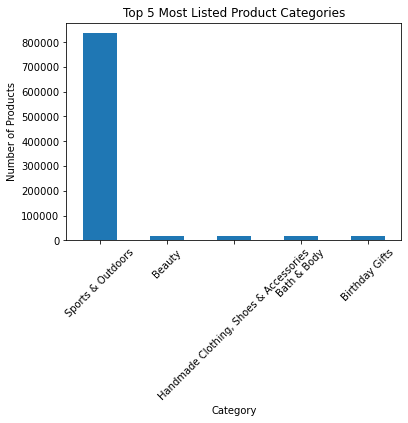

In [5]:
top_5_categories = category_counts.head(5)

top_5_categories.plot(kind="bar")

plt.title("Top 5 Most Listed Product Categories")
plt.xlabel("Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=45)
plt.show()

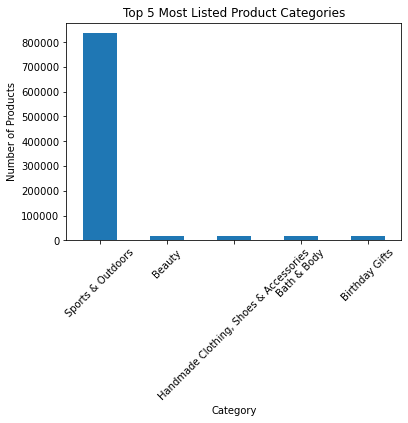

In [6]:
top_5_categories = category_counts.head(5)

top_5_categories.plot(kind="bar")

plt.title("Top 5 Most Listed Product Categories")
plt.xlabel("Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=45)
plt.show()

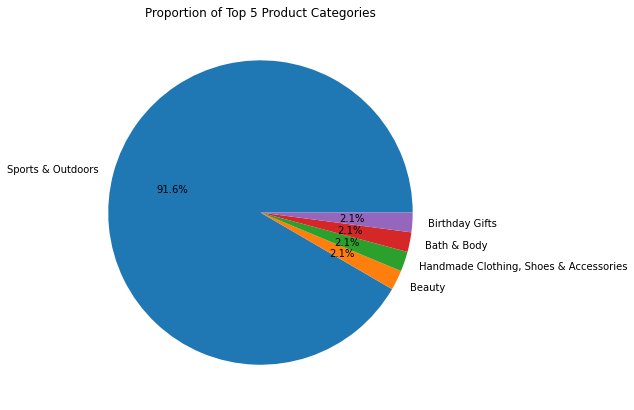

In [7]:
top_5_categories.plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(7, 7)
)

plt.title("Proportion of Top 5 Product Categories")
plt.ylabel("")
plt.show()

In [ ]:
Part 1 – Product Categories
Sports & Outdoors is the most frequently listed category by a large margin. The other top categories have much lower and relatively similar listing counts, so Sports & Outdoors clearly dominates the top-category distribution.

In [8]:
mean_price = df["price"].mean()
median_price = df["price"].median()
mode_price = df["price"].mode()[0]

print("Mean price:", mean_price)
print("Median price:", median_price)
print("Mode price:", mode_price)

Mean price: 89.24380943985244
Median price: 19.09
Mode price: 9.99


In [9]:
variance_price = df["price"].var()
std_price = df["price"].std()
range_price = df["price"].max() - df["price"].min()
iqr_price = df["price"].quantile(0.75) - df["price"].quantile(0.25)

print("Variance:", variance_price)
print("Standard deviation:", std_price)
print("Range:", range_price)
print("IQR:", iqr_price)

Variance: 119445.48532256528
Standard deviation: 345.60886175352226
Range: 100000.0
IQR: 36.0


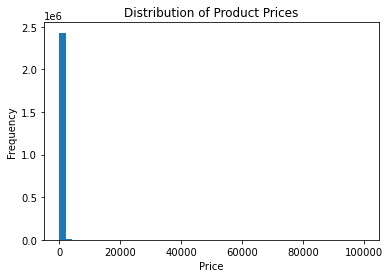

In [10]:
df["price"].plot(kind="hist", bins=50)

plt.title("Distribution of Product Prices")
plt.xlabel("Price")
plt.show()

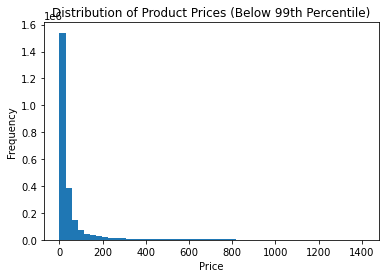

In [11]:
price_limit = df["price"].quantile(0.99)

df[df["price"] <= price_limit]["price"].plot(
    kind="hist",
    bins=50
)

plt.title("Distribution of Product Prices (Below 99th Percentile)")
plt.xlabel("Price")
plt.show()

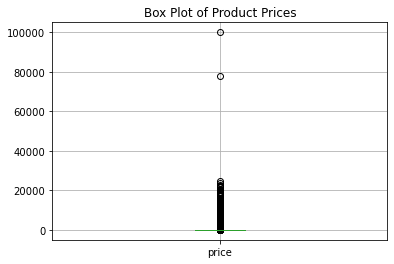

In [12]:
df.boxplot(column="price")

plt.title("Box Plot of Product Prices")
plt.show()

In [ ]:
Part 2 – Product Pricing
The difference between the mean, median, and mode suggests that product prices are not evenly distributed. The large spread, standard deviation, range, and visible outliers indicate that Amazon UK contains many low-to-mid priced products together with a smaller number of very expensive products. Because those extreme prices distort the histogram, looking at a filtered range such as below the 99th percentile gives a clearer view of the typical price distribution.

In [13]:
mean_rating = df["stars"].mean()
median_rating = df["stars"].median()
mode_rating = df["stars"].mode()[0]

print("Mean rating:", mean_rating)
print("Median rating:", median_rating)
print("Mode rating:", mode_rating)

Mean rating: 2.152836472966905
Median rating: 0.0
Mode rating: 0.0


In [14]:
variance_rating = df["stars"].var()
std_rating = df["stars"].std()
iqr_rating = df["stars"].quantile(0.75) - df["stars"].quantile(0.25)

print("Variance:", variance_rating)
print("Standard deviation:", std_rating)
print("IQR:", iqr_rating)

Variance: 4.81743402976196
Standard deviation: 2.1948653785054697
IQR: 4.4


In [15]:
skewness_rating = df["stars"].skew()
kurtosis_rating = df["stars"].kurt()

print("Skewness:", skewness_rating)
print("Kurtosis:", kurtosis_rating)

Skewness: 0.08120735761080985
Kurtosis: -1.9260061280432985


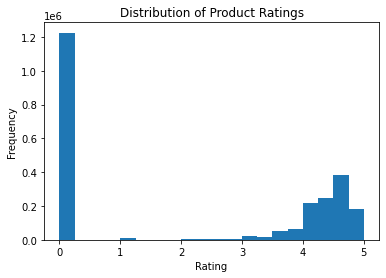

In [16]:
df["stars"].plot(kind="hist", bins=20)

plt.title("Distribution of Product Ratings")
plt.xlabel("Rating")
plt.show()

In [ ]:
Part 3 – Product Ratings
The ratings show how customers generally evaluate products and whether feedback is concentrated around certain values. The measures of dispersion indicate how consistent the ratings are, while skewness and kurtosis help describe the shape of the distribution. The histogram makes it easier to see which rating values occur most frequently.